# 01 - Data audit and cleaning

**Question this notebook answers:** what is actually in the sensor data, how trustworthy is it, and what does the cleaning step do to it before any model sees it?

**How to run:** start Jupyter from the repository root, with the three data files in `data/raw/` (see `data/README.md`). The first run turns the 1.6 GB occupancy file into 5-minute averages (about 10-30 s) and caches them in `data/processed/`.

The checks use the tested functions in `src/occupancy_forecast/audit.py` and `cleaning.py`, so every number here can be reproduced from the repository.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# find the repository root (works whether Jupyter is started in the root or in notebooks/)
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "occupancy_forecast").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

RAW = ROOT / "data" / "raw"
OCC = RAW / "5occupancySensor_MayToDec2024_9MRows.csv"
ENV = RAW / "5EnvSensor_MayToDec2024_180kRows.csv"
LOOKUP = RAW / "Sensor_ID_and_Locations.xlsx"
CACHE = ROOT / "data" / "processed" / "binned_5min.parquet"
RESULTS = ROOT / "results"

In [2]:
# 5-minute averages of the 9.1M raw readings (computed once, then cached in data/processed/)
if CACHE.exists():
    binned = pd.read_parquet(CACHE)
else:
    from occupancy_forecast.data_loading import resample_occupancy
    binned = resample_occupancy(OCC, 5)
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    binned.to_parquet(CACHE)

def room_names(ids):
    """Readable room names from the location lookup where it has them, else the first 8 characters of the ID."""
    names = {i: i[:8] for i in ids}
    if LOOKUP.exists():
        occ = pd.read_excel(LOOKUP, sheet_name=1)
        for sid, room in zip(occ["SpaceId"], occ["Floor/Room"]):
            if sid in names:
                names[sid] = str(room)
    return names

NAMES = room_names(sorted(binned["floorspaceid"].unique()))
ROOMS = list(NAMES)
COLORS = dict(zip(ROOMS, plt.cm.tab10.colors))
COLOR_OF = {NAMES[r]: COLORS[r] for r in ROOMS}      # colour by room *name*, so a room looks the same in every figure

## 1. The raw files

In [3]:
from occupancy_forecast.audit import (audit_id_match_rate, audit_timestamp_range, audit_variable_completeness,
                                       count_distinct, parse_env_sensor_csv)

occ_range = audit_timestamp_range(OCC, "collecteddate")
env_range = audit_timestamp_range(ENV, "createdate")
tidy = parse_env_sensor_csv(ENV)                        # nested JSON -> one row per (sensor, time, variable)
n_env_readings = tidy[["sensorid", "timestamp"]].drop_duplicates().shape[0]

files = pd.DataFrame({
    "occupancy sensors": {
        "rows": int(binned["n_obs"].sum()), "distinct device IDs": count_distinct(OCC, "deviceid"),
        "distinct rooms / sensors": count_distinct(OCC, "floorspaceid"),
        "first reading": occ_range["min_timestamp"].strftime("%Y-%m-%d"),
        "last reading": occ_range["max_timestamp"].strftime("%Y-%m-%d"), "span (days)": round(occ_range["span_days"])},
    "environmental sensors": {
        "rows": n_env_readings, "distinct device IDs": "-",
        "distinct rooms / sensors": tidy["sensorid"].nunique(),
        "first reading": env_range["min_timestamp"].strftime("%Y-%m-%d"),
        "last reading": env_range["max_timestamp"].strftime("%Y-%m-%d"), "span (days)": round(env_range["span_days"])},
})
display(files)
display(Markdown(
    f"- Both file names say **May to Dec 2024**, but the occupancy readings run from **{occ_range['min_timestamp']:%b %Y}** "
    f"to **{occ_range['max_timestamp']:%b %Y}** ({occ_range['span_days']:.0f} days).\n"
    f"- The occupancy file holds **{count_distinct(OCC, 'deviceid')} device ID for {count_distinct(OCC, 'floorspaceid')} rooms**: "
    f"one hub reports for all of them, so `deviceid` cannot tell the rooms apart; `floorspaceid` does."))

,occupancy sensors,environmental sensors
rows,9091732,179447
distinct device IDs,1,-
distinct rooms / sensors,5,5
first reading,2023-11-23,2024-02-28
last reading,2026-04-22,2026-04-22
span (days),881,784


- Both file names say **May to Dec 2024**, but the occupancy readings run from **Nov 2023** to **Apr 2026** (881 days).
- The occupancy file holds **1 device ID for 5 rooms**: one hub reports for all of them, so `deviceid` cannot tell the rooms apart; `floorspaceid` does.

## 2. Can the two sensor types be tied to the same rooms?

The supplied lookup spreadsheet maps sensor IDs to rooms. Its occupancy sheet is labelled "Incorrect Data" by its authors, so the first thing to check is how many IDs in the data it actually knows about.

In [4]:
if LOOKUP.exists():
    occ_lookup = pd.read_excel(LOOKUP, sheet_name=1)            # sheet name is truncated by Excel, so use its position
    env_lookup = pd.read_excel(LOOKUP, sheet_name="ENV")
    occ_link = audit_id_match_rate(set(binned["floorspaceid"].unique()), occ_lookup["SpaceId"])
    env_link = audit_id_match_rate(set(tidy["sensorid"].unique()), env_lookup["ID"].astype(str))
    occ_rooms = set(occ_lookup.loc[occ_lookup["SpaceId"].isin(occ_link["matched_ids"]), "Floor/Room"].astype(str))
    env_rooms = set(env_lookup.loc[env_lookup["ID"].astype(str).isin(env_link["matched_ids"]), "Floor/Room"].astype(str))
    link = pd.DataFrame({
        "IDs in the data": [occ_link["n_data_ids"], env_link["n_data_ids"]],
        "found in lookup": [occ_link["n_matched"], env_link["n_matched"]],
        "match rate": [f"{occ_link['match_rate']:.0%}", f"{env_link['match_rate']:.0%}"],
        "rooms identified": [", ".join(sorted(occ_rooms)) or "none", ", ".join(sorted(env_rooms)) or "none"]},
        index=["occupancy rooms", "environmental sensors"])
    display(link)
    shared = occ_rooms & env_rooms
    display(Markdown("**Rooms identified for both sensor types:** " + (", ".join(sorted(shared)) if shared else
            "**none**. The environmental readings cannot be joined to the occupancy readings by room, "
            "which is why this project forecasts occupancy from the occupancy stream itself.")))
else:
    display(Markdown("*`Sensor_ID_and_Locations.xlsx` not found in `data/raw/`; skipping the lookup check.*"))

,IDs in the data,found in lookup,match rate,rooms identified
occupancy rooms,5,2,40%,"G.20, G.25"
environmental sensors,5,1,20%,G.38


**Rooms identified for both sensor types:** **none**. The environmental readings cannot be joined to the occupancy readings by room, which is why this project forecasts occupancy from the occupancy stream itself.

## 3. How complete are the environmental readings?

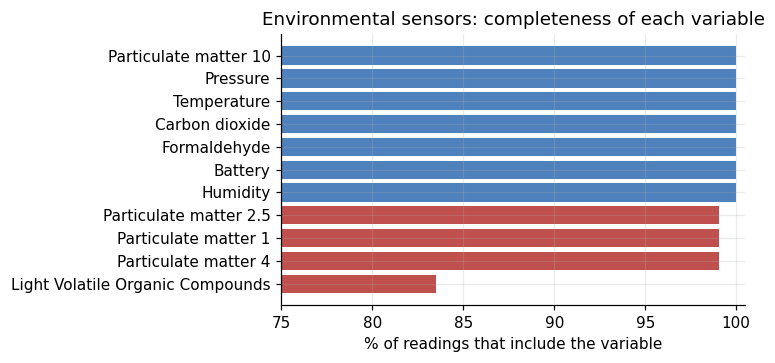

variable,Battery,Carbon dioxide,Formaldehyde,Humidity,Particulate matter 10,Pressure,Temperature,Particulate matter 4,Particulate matter 1,Particulate matter 2.5,Light Volatile Organic Compounds
% complete,100.0,100.0,100.0,100.0,100.0,100.0,100.0,99.0,99.0,99.0,83.5


In [5]:
completeness = audit_variable_completeness(tidy)
fig, ax = plt.subplots(figsize=(7, 3.4))
c = completeness["completeness"].sort_values()
ax.barh(c.index, c * 100, color=["#c0504d" if v < 0.999 else "#4f81bd" for v in c])
ax.set_xlim(75, 100.5); ax.set_xlabel("% of readings that include the variable")
ax.set_title("Environmental sensors: completeness of each variable")
plt.tight_layout(); plt.show()
display((completeness["completeness"] * 100).round(1).rename("% complete").to_frame().T)

Most variables are complete; the volatile organic compound and some particulate-matter readings are missing from a noticeable share of readings. A quick look at only the first 20,000 rows would have shown 100% for everything, which is why the check runs on the whole file.

## 4. How much of the 5-minute timeline has readings, and where are the gaps?

The occupancy hub only reports when it has something to say. Putting each room on a complete 5-minute timeline shows how much of it is empty.

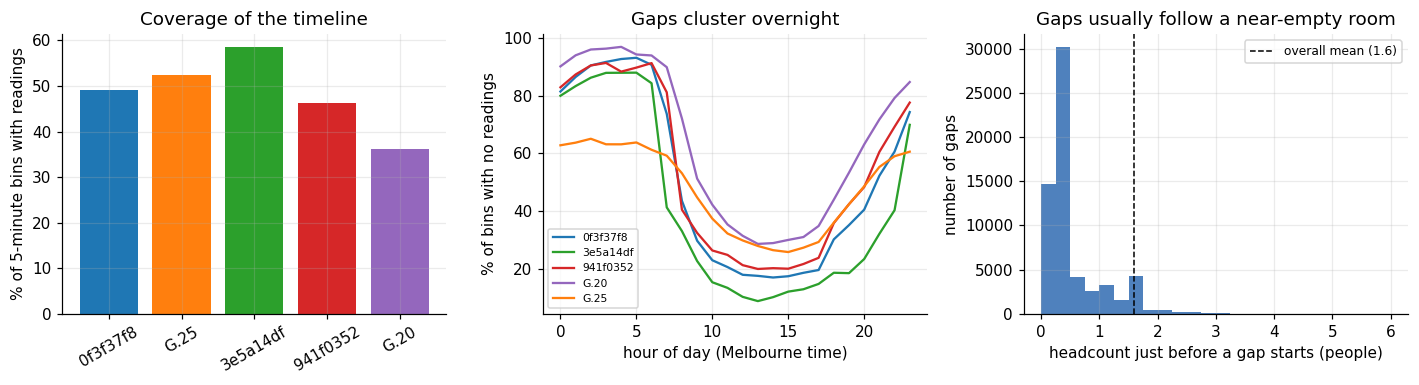

- Coverage ranges from **36%** to **58%** of the timeline.
- **76%** of gaps start after a bin averaging 0.5 people or fewer (overall mean headcount is 1.6).

In [6]:
from occupancy_forecast.cleaning import regularize_grid

grid = regularize_grid(binned, 5)
grid["observed"] = grid["mean_headcount_raw"].notna()
grid["room"] = grid["floorspaceid"].map(NAMES)
coverage = grid.groupby("room")["observed"].mean().reindex([NAMES[r] for r in ROOMS])

# share of timeline bins with no readings, by local hour of day
by_hour = (1 - grid.groupby(["room", grid["timestamp"].dt.hour])["observed"].mean()).unstack(0)

# headcount in the bin just before each gap starts
g = grid.sort_values(["floorspaceid", "timestamp"]).reset_index(drop=True)
missing = ~g["observed"]
starts = missing & ~missing.groupby(g["floorspaceid"]).shift(1, fill_value=False)
before_gap = g.groupby("floorspaceid")["mean_headcount_raw"].shift(1)[starts].dropna()
overall_mean = g["mean_headcount_raw"].mean()

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].bar(coverage.index, coverage * 100, color=[COLORS[r] for r in ROOMS])
axes[0].set_ylabel("% of 5-minute bins with readings"); axes[0].set_title("Coverage of the timeline")
axes[0].tick_params(axis="x", rotation=30)
for room in by_hour.columns:
    axes[1].plot(by_hour.index, by_hour[room] * 100, label=room, color=COLOR_OF[room])
axes[1].set_xlabel("hour of day (Melbourne time)"); axes[1].set_ylabel("% of bins with no readings")
axes[1].set_title("Gaps cluster overnight"); axes[1].legend(fontsize=7)
axes[2].hist(before_gap.clip(upper=6), bins=np.arange(0, 6.25, 0.25), color="#4f81bd")
axes[2].axvline(overall_mean, color="k", ls="--", lw=1, label=f"overall mean ({overall_mean:.1f})")
axes[2].set_xlabel("headcount just before a gap starts (people)"); axes[2].set_ylabel("number of gaps")
axes[2].set_title("Gaps usually follow a near-empty room"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

display(Markdown(f"- Coverage ranges from **{coverage.min():.0%}** to **{coverage.max():.0%}** of the timeline.\n"
                 f"- **{(before_gap <= 0.5).mean():.0%}** of gaps start after a bin averaging 0.5 people or fewer "
                 f"(overall mean headcount is {overall_mean:.1f})."))

**Reading this:** gaps are concentrated overnight and usually begin after the room was nearly empty. The most plausible explanation is that the hub stays quiet when nothing is happening. That is an *inference from timing*, not something the data proves; no ground truth exists for why the hub is silent. The cleaning step below acts on this inference through one adjustable setting, and notebook 03 shows how much the forecasts depend on it.

## 5. What the cleaning step does

`clean_occupancy` applies three rules, each keeping the original value and recording what was done:

1. **Cap spikes:** a bin more than 5 people above its local rolling median is capped (the raw value is kept alongside).
2. **Interpolate short gaps:** gaps up to 15 minutes are filled in a straight line between the readings on either side.
3. **Fill quiet gaps with zero:** gaps up to one day that follow a bin of 0.5 people or fewer are filled with 0 (`assumed_empty`). All other gaps stay missing.

fill_status,n_bins,observed %,interpolated %,assumed empty %,missing %,n_spikes,max_raw
0f3f37f8,253710,49.2,5.0,36.7,9.1,217,28.380597
G.25,224725,52.5,9.6,32.6,5.3,249,29.000000
3e5a14df,70261,58.5,4.6,26.9,10.0,49,29.710938
941f0352,253710,46.3,5.7,40.4,7.7,15,10.213483
G.20,224734,36.1,3.7,42.9,17.3,373,66.763158


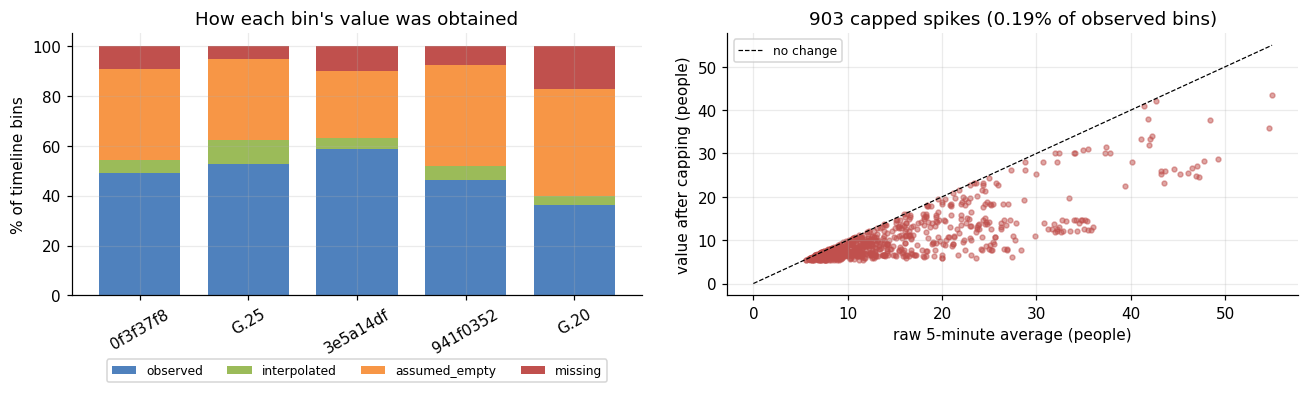

In [7]:
from occupancy_forecast.cleaning import clean_occupancy, cleaning_summary

clean = clean_occupancy(binned)
summary = cleaning_summary(clean)
summary.index = [NAMES[i] for i in summary.index]
display((summary.assign(**{c: (summary[c] * 100).round(1) for c in ["observed", "interpolated", "assumed_empty", "missing"]})
         .rename(columns={"observed": "observed %", "interpolated": "interpolated %", "assumed_empty": "assumed empty %",
                          "missing": "missing %"})))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
shares = summary[["observed", "interpolated", "assumed_empty", "missing"]] * 100
shares.plot.bar(stacked=True, ax=axes[0], color=["#4f81bd", "#9bbb59", "#f79646", "#c0504d"], width=0.75)
axes[0].set_ylabel("% of timeline bins"); axes[0].set_title("How each bin's value was obtained")
axes[0].legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22)); axes[0].tick_params(axis="x", rotation=30)
spikes = clean[clean["is_spike"]]
capped = clean.merge(spikes[["floorspaceid", "timestamp"]], on=["floorspaceid", "timestamp"])
axes[1].scatter(capped["mean_headcount_raw"], capped["headcount"], s=10, alpha=0.5, color="#c0504d")
lim = max(capped["mean_headcount_raw"].max(), 1)
axes[1].plot([0, lim], [0, lim], "k--", lw=0.8, label="no change")
axes[1].set_xlabel("raw 5-minute average (people)"); axes[1].set_ylabel("value after capping (people)")
axes[1].set_title(f"{len(spikes)} capped spikes ({len(spikes) / clean['mean_headcount_raw'].notna().sum():.2%} of observed bins)")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading this:** a large share of the usable timeline (the orange "assumed empty" bars) rests on the quiet-hub inference, so it is the assumption most worth testing. The cap changes very few values, and keeps the raw one so nothing is lost.

## 6. From 9 million readings to training examples

In [8]:
from occupancy_forecast.features import build_supervised_dataset
from occupancy_forecast.validation import chronological_split

data = build_supervised_dataset(clean, horizon_minutes=30)
train, val, test = chronological_split(data)
status = clean["fill_status"].value_counts()
usable = int((clean["fill_status"] != "missing").sum())
flow = pd.DataFrame({"count": [
    int(binned["n_obs"].sum()), len(binned), len(clean), usable, len(data), len(train), len(val), len(test)]},
    index=["raw sensor readings", "5-minute bins with readings", "bins on the complete timeline",
           "  of which usable (not missing)", "forecast examples (30 min ahead)", "  training", "  validation", "  test (sealed until the end)"])
flow["share of timeline"] = (flow["count"] / len(clean) * 100).round(1).astype(str) + " %"
flow.loc["raw sensor readings", "share of timeline"] = "-"
display(flow)
display(Markdown(f"- Bins left **missing** and excluded: **{status.get('missing', 0):,}** ({status.get('missing', 0) / len(clean):.1%} of the timeline).\n"
                 f"- Further examples lost because a bin in the previous hour, or the target 30 minutes ahead, is missing: "
                 f"**{usable - len(data):,}**."))

,count,share of timeline
raw sensor readings,9091732,-
5-minute bins with readings,482538,47.0 %
bins on the complete timeline,1027140,100.0 %
of which usable (not missing),926869,90.2 %
forecast examples (30 min ahead),867719,84.5 %
training,520600,50.7 %
validation,173513,16.9 %
test (sealed until the end),173546,16.9 %


- Bins left **missing** and excluded: **100,271** (9.8% of the timeline).
- Further examples lost because a bin in the previous hour, or the target 30 minutes ahead, is missing: **59,150**.

## 7. What this audit shows, and what it cannot show

**Shows**
- The files cover Nov 2023 to Apr 2026, not May to Dec 2024, and one hub reports for five rooms.
- The environmental and occupancy data cannot be linked by room using the supplied lookup, so the project forecasts occupancy from the occupancy stream alone.
- Only about half the timeline has readings; gaps cluster overnight and follow near-empty rooms.
- The 9.1 million raw readings are about 0.5 million 5-minute averages, and roughly 0.87 million forecast examples once the full timeline is built.

**Cannot show**
- *Why* the hub goes quiet (a quiet room, or a dropout). The cleaning rule treats it as empty; the sensitivity results in notebook 03 test how much that matters.
- Whether `headcount` is correct. There is no independent count to compare it with, so the project forecasts what the sensor reports.
- Anything about other buildings: it is five rooms in one building.